PEN: 250843116018

Practical_5: Analyze datasets using correlation, covariance, outlier detection, and distribution analysis.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data={"Student_id":[101,102,103,104,105,106,107,108,109,110,111,112,113,114,115],
      "study_hours":[ 2,3,4,5,6,7,8,9,3,4,5,6,7,10,1],
      "attendance": [65,70,75,80,82,90,92,68,74,78,84,88,95,40,35],
      "assignment_score":[55,60,65,70,72,78,82,88,62,67,71,76,80,95,35],
      "final_marks":[50,55,62,68,72,78,82,90,58,63,69,75,81,98,25]}

df = pd.DataFrame(data)
df

,Student_id,study_hours,attendance,assignment_score,final_marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72
5,106,7,90,78,78
6,107,8,92,82,82
7,108,9,68,88,90
8,109,3,74,62,58
9,110,4,78,67,63


In [3]:

df.head()

,Student_id,study_hours,attendance,assignment_score,final_marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72


In [4]:
# for print 1st 5 record
df.head()

,Student_id,study_hours,attendance,assignment_score,final_marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72


In [5]:
# to know many rows and collumns
df.shape

(15, 5)

In [6]:
# chec the coorelation between study hours and marks
cor = df["study_hours"].corr(df["final_marks"])

print(f"Correlation between Study_Hours and Final_Marks: {cor}")

Correlation between Study_Hours and Final_Marks: 0.9626650934516625


In [7]:
# To print whole correlation matrix
correlation_matrix = df.corr()
print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
                  Student_id  study_hours  attendance  assignment_score  \
Student_id          1.000000     0.247436   -0.269776          0.136585   
study_hours         0.247436     1.000000    0.222508          0.961552   
attendance         -0.269776     0.222508    1.000000          0.347135   
assignment_score    0.136585     0.961552    0.347135          1.000000   
final_marks         0.128606     0.962665    0.354828          0.999268   

                  final_marks  
Student_id           0.128606  
study_hours          0.962665  
attendance           0.354828  
assignment_score     0.999268  
final_marks          1.000000  


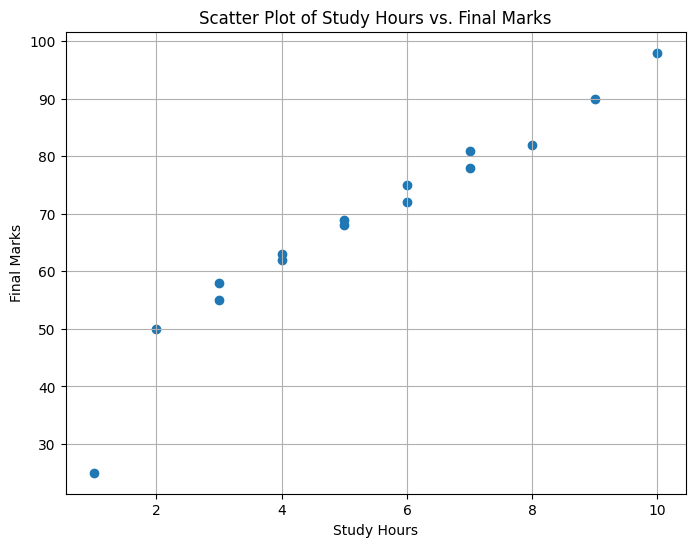

In [8]:
# scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df['study_hours'], df['final_marks'])
plt.title('Scatter Plot of Study Hours vs. Final Marks')
plt.xlabel('Study Hours')
plt.ylabel('Final Marks')
plt.grid(True)
plt.show()

In [9]:
# calculating covariance to check directional relationship
covariance_study_final = df['study_hours'].cov(df['final_marks'])
print(f"Covariance between Study_Hours and Final_Marks: {covariance_study_final}")

Covariance between Study_Hours and Final_Marks: 44.14285714285714


In [10]:
# selecting numerical columns and removing ID because it useless for math
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

if 'Student_id' in numerical_cols:
    numerical_cols.remove('Student_id')
df_numerical = df[numerical_cols]
print("Numerical columns selected for covariance analysis:")
print(numerical_cols)

Numerical columns selected for covariance analysis:
['study_hours', 'attendance', 'assignment_score', 'final_marks']


In [11]:
# calculating the covarience matrix
covariance_matrix = df_numerical.cov()
print("Covariance Matrix:")
print(covariance_matrix)

Covariance Matrix:
                  study_hours  attendance  assignment_score  final_marks
study_hours          6.666667   10.000000         36.000000    44.142857
attendance          10.000000  302.971429         87.614286   109.685714
assignment_score    36.000000   87.614286        210.257143   257.328571
final_marks         44.142857  109.685714        257.328571   315.400000


In [12]:
# using IQR method to find outliers in final marks
Q1 = df['final_marks'].quantile(0.25)  # Calculate the first quartile (Q1)
Q3 = df['final_marks'].quantile(0.75)  # Calculate the third quartile (Q3)

IQR = Q3 - Q1  # Interquartile Range (IQR)
lower_bound = Q1 - 1.5 * IQR  # lower limit for detecting outliers
upper_bound = Q3 + 1.5 * IQR  # upper limit for detecting outliers

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

# Find values that are below the lower bound or above the upper bound
outliers = df[
    (df['final_marks'] < lower_bound) |
    (df['final_marks'] > upper_bound)
]

print("\nOutliers detected:")
print(outliers)

Q1: 60.0, Q3: 79.5, IQR: 19.5
Lower Bound: 30.75, Upper Bound: 108.75

Outliers detected:
    Student_id  study_hours  attendance  assignment_score  final_marks
14         115            1          35                35           25


In [13]:
# printing out just the outlier rows
outliers = df[(df['final_marks'] < lower_bound) | (df['final_marks'] > upper_bound)]

print("Outliers:")
print(outliers)

Outliers:
    Student_id  study_hours  attendance  assignment_score  final_marks
14         115            1          35                35           25


In [14]:
# count of how many extreme values
num_outliers = len(outliers)
print(f"Total number of detected outliers: {num_outliers}")

Total number of detected outliers: 1


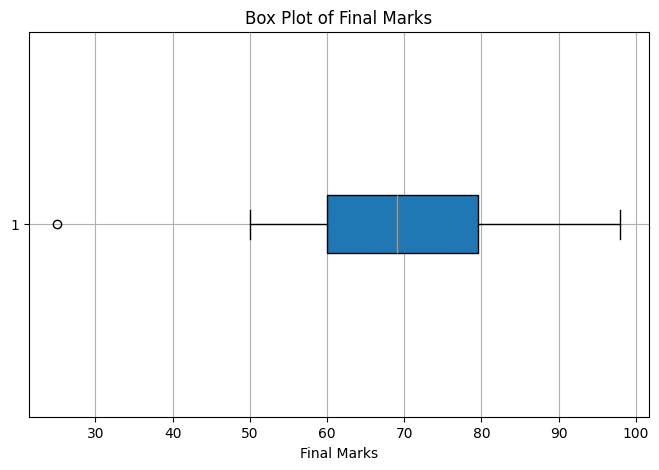

In [15]:
# boxplot to visualy see the outliers
plt.figure(figsize=(8, 5))
plt.boxplot(df['final_marks'], vert=False, patch_artist=True)
plt.title('Box Plot of Final Marks')
plt.xlabel('Final Marks')
plt.grid(True)
plt.show()

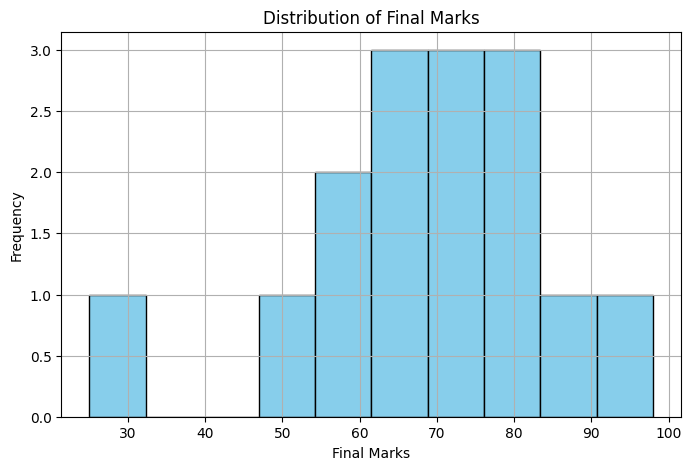

Skewness of Final Marks: -0.7383380071904277


In [16]:
# ploting distribution of final marks and checking skewness
plt.figure(figsize=(8, 5))
plt.hist(df['final_marks'], bins=10, edgecolor='black', color='skyblue')
plt.title('Distribution of Final Marks')
plt.xlabel('Final Marks')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

skewness_final_marks = df['final_marks'].skew()
print(f"Skewness of Final Marks: {skewness_final_marks}")

In [17]:
# printing skewness to check symetry of marks
skewness_final_marks = df['final_marks'].skew()
print(f"Skewness of Final Marks: {skewness_final_marks}")

Skewness of Final Marks: -0.7383380071904277


In [18]:
# calculating kurtosis
kurtosis_final_marks = df['final_marks'].kurtosis()
print(f"Kurtosis of Final Marks: {kurtosis_final_marks}")

Kurtosis of Final Marks: 1.4936683306648835


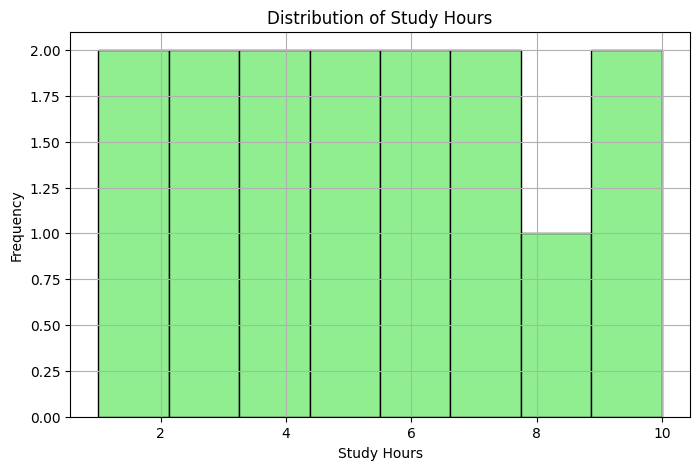

In [19]:
# displaying how study hours are distributed among students
plt.figure(figsize=(8, 5))
plt.hist(df['study_hours'], bins=8, edgecolor='black', color='lightgreen')
plt.title('Distribution of Study Hours')
plt.xlabel('Study Hours')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

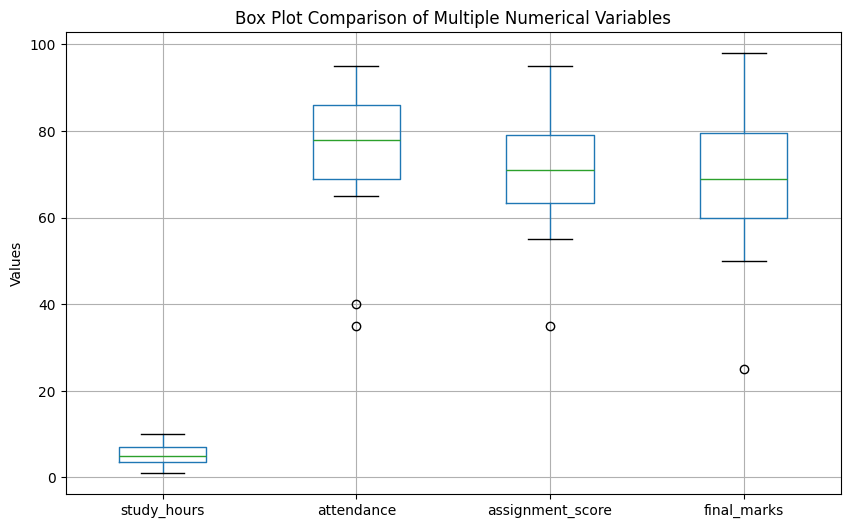

In [20]:
# comparing all box plots in one graph to see spread
plt.figure(figsize=(10, 6))
df[['study_hours', 'attendance', 'assignment_score', 'final_marks']].boxplot()
plt.title('Box Plot Comparison of Multiple Numerical Variables')
plt.ylabel('Values')
plt.grid(True)
plt.show()

In [21]:
# statistical data
df.describe()

,Student_id,study_hours,attendance,assignment_score,final_marks
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,108.000000,5.333333,74.400000,70.400000,68.400000
std,4.472136,2.581989,17.406074,14.500246,17.759504
min,101.000000,1.000000,35.000000,35.000000,25.000000
25%,104.500000,3.500000,69.000000,63.500000,60.000000
50%,108.000000,5.000000,78.000000,71.000000,69.000000
75%,111.500000,7.000000,86.000000,79.000000,79.500000
max,115.000000,10.000000,95.000000,95.000000,98.000000


In [22]:
# saving final dataset
df.to_csv('Dataset_analysis.csv', index=False)
print("Dataset saved successfully as 'Dataset_analysis.csv'")

Dataset saved successfully as 'Dataset_analysis.csv'


In [23]:
# importing and downloading files from colab enviroment
from google.colab import files

# Download the CSV file.
files.download("Dataset_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>